# Phân tích dữ liệu Vietlott

Notebook này khám phá dữ liệu lịch sử của **Mega 6/45** và **Power 6/55**:
tần suất xuất hiện, khoảng cách giữa các lần về (gap), tần suất gần đây,
cặp số xuất hiện cùng nhau, phân bố theo thời gian và phân bố đặc trưng
dùng cho mô hình.

> Dữ liệu cần có sẵn trong `data/raw/`. Nếu chưa có, chạy:
> `python -m vietlott_ml.cli bootstrap --lottery all`
> (và `collect --lottery all` để lấy kỳ mới nhất).

**Lưu ý trung thực:** xổ số là quá trình ngẫu nhiên. Phân tích dưới đây
mô tả dữ liệu quá khứ, không hàm ý dự đoán được kỳ tiếp theo.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from vietlott_ml.config import LOTTERIES
from vietlott_ml.dataset import FEATURE_NAMES, load_matrix, make_tabular

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")
print("Repo:", ROOT)

Repo: /mnt/d/Vietlott_VN


## 1. Tổng quan dữ liệu

In [2]:
draws_by_lottery = {}
matrices = {}

rows = []
for key, cfg in LOTTERIES.items():
    draws, matrix = load_matrix(key)
    draws_by_lottery[key] = draws
    matrices[key] = matrix
    dates = [d.date for d in draws]
    rows.append(
        {
            "lottery": cfg["name"],
            "key": key,
            "n_draws": len(draws),
            "n_features": cfg["n_features"],
            "pick": cfg["pick"],
            "start": min(dates),
            "end": max(dates),
        }
    )

overview = pd.DataFrame(rows)
overview

,lottery,key,n_draws,n_features,pick,start,end
0,Mega 6/45,mega645,1389,45,6,2017-10-25,2026-11-08
1,Power 6/55,power655,1421,55,6,2017-08-01,2026-11-10


## 2. Ma trận multi-hot

Mỗi hàng là một kỳ, mỗi cột là một số. Giá trị `1` nghĩa là số đó xuất
hiện trong kỳ. Đây là biểu diễn gốc cho mọi phân tích và mô hình.

In [3]:
key = "mega645"
matrix = matrices[key]
draws = draws_by_lottery[key]
n_show = 8
n_cols = 20

preview = pd.DataFrame(
    matrix[:n_show, :n_cols].astype(int),
    columns=[f"Số {i}" for i in range(1, n_cols + 1)],
    index=[d.draw_id for d in draws[:n_show]],
)
preview.index.name = "draw_id"
preview

,Số 1,Số 2,Số 3,Số 4,Số 5,Số 6,Số 7,Số 8,Số 9,Số 10,Số 11,Số 12,Số 13,Số 14,Số 15,Số 16,Số 17,Số 18,Số 19,Số 20
draw_id,,,,,,,,,,,,,,,,,,,,
00198,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0
00199,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0
00200,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
00201,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
00202,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1
00203,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
00204,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
00205,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


## 3. Tần suất xuất hiện của từng số

`expected` là số lần kỳ vọng nếu xổ số hoàn toàn ngẫu nhiên:
`n_draws * pick / n_features`. Chênh lệch lớn chỉ phản ánh dao động
ngẫu nhiên của mẫu hữu hạn.

In [4]:
def frequency_table(lottery: str) -> pd.DataFrame:
    cfg = LOTTERIES[lottery]
    m = matrices[lottery]
    n = m.shape[0]
    counts = m.sum(axis=0).astype(int)
    expected = n * cfg["pick"] / cfg["n_features"]
    df = pd.DataFrame(
        {
            "number": np.arange(1, cfg["n_features"] + 1),
            "count": counts,
            "pct": counts / n,
            "expected": expected,
            "delta": counts - expected,
        }
    )
    return df.sort_values("count", ascending=False).reset_index(drop=True)

freq_tables = {k: frequency_table(k) for k in LOTTERIES}

for k, df in freq_tables.items():
    print(f"### {LOTTERIES[k]['name']} — 10 số xuất hiện nhiều nhất")
    display(df.head(10).round(3))
    print("10 số xuất hiện ít nhất")
    display(df.tail(10).iloc[::-1].round(3))

### Mega 6/45 — 10 số xuất hiện nhiều nhất


,number,count,pct,expected,delta
0,10,205,0.148,185.2,19.8
1,22,205,0.148,185.2,19.8
2,7,203,0.146,185.2,17.8
3,44,201,0.145,185.2,15.8
4,24,200,0.144,185.2,14.8
5,19,200,0.144,185.2,14.8
6,37,199,0.143,185.2,13.8
7,20,199,0.143,185.2,13.8
8,28,198,0.143,185.2,12.8
9,41,195,0.140,185.2,9.8


10 số xuất hiện ít nhất


,number,count,pct,expected,delta
44,17,162,0.117,185.2,-23.2
43,38,165,0.119,185.2,-20.2
42,32,165,0.119,185.2,-20.2
41,21,169,0.122,185.2,-16.2
40,12,169,0.122,185.2,-16.2
39,3,170,0.122,185.2,-15.2
38,39,173,0.125,185.2,-12.2
37,15,173,0.125,185.2,-12.2
36,40,174,0.125,185.2,-11.2
35,2,175,0.126,185.2,-10.2


### Power 6/55 — 10 số xuất hiện nhiều nhất


,number,count,pct,expected,delta
0,22,181,0.127,155.018,25.982
1,41,179,0.126,155.018,23.982
2,51,174,0.122,155.018,18.982
3,34,171,0.120,155.018,15.982
4,29,171,0.120,155.018,15.982
5,8,169,0.119,155.018,13.982
6,32,169,0.119,155.018,13.982
7,43,167,0.118,155.018,11.982
8,11,167,0.118,155.018,11.982
9,9,165,0.116,155.018,9.982


10 số xuất hiện ít nhất


,number,count,pct,expected,delta
54,4,126,0.089,155.018,-29.018
53,28,131,0.092,155.018,-24.018
52,37,133,0.094,155.018,-22.018
51,15,134,0.094,155.018,-21.018
50,6,135,0.095,155.018,-20.018
49,2,140,0.099,155.018,-15.018
48,35,142,0.100,155.018,-13.018
47,36,143,0.101,155.018,-12.018
46,7,143,0.101,155.018,-12.018
45,54,144,0.101,155.018,-11.018


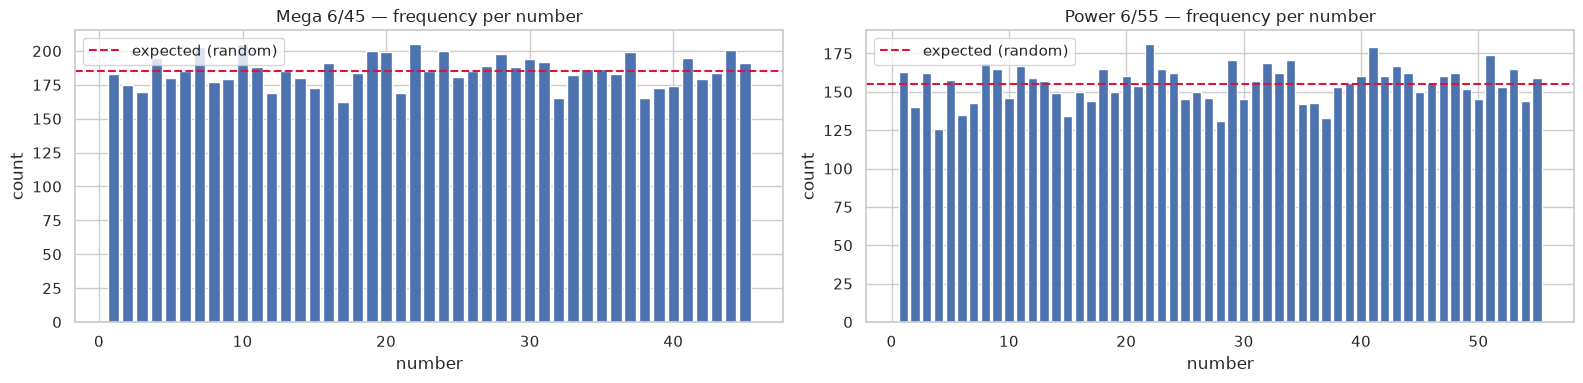

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, (k, df) in zip(axes, freq_tables.items(), strict=True):
    ordered = df.sort_values("number")
    ax.bar(ordered["number"], ordered["count"], color="#4c72b0")
    ax.axhline(
        ordered["expected"].iloc[0],
        color="crimson",
        linestyle="--",
        label="expected (random)",
    )
    ax.set_title(f"{LOTTERIES[k]['name']} — frequency per number")
    ax.set_xlabel("number")
    ax.set_ylabel("count")
    ax.legend()
plt.tight_layout()
plt.show()

## 4. Khoảng cách giữa các lần về (gap)

Với mỗi số: số lần xuất hiện, gap trung bình, gap lớn nhất và số kỳ đã
trôi qua kể từ lần về gần nhất (`current_gap`).

In [6]:
def gap_stats(lottery: str) -> pd.DataFrame:
    m = matrices[lottery]
    n, n_features = m.shape
    rows = []
    for j in range(n_features):
        idx = np.flatnonzero(m[:, j])
        gaps = np.diff(idx) if len(idx) > 1 else np.array([])
        current_gap = (n - 1 - idx[-1]) if len(idx) else n
        rows.append(
            {
                "number": j + 1,
                "n_appear": len(idx),
                "mean_gap": gaps.mean() if len(gaps) else np.nan,
                "max_gap": gaps.max() if len(gaps) else np.nan,
                "current_gap": int(current_gap),
            }
        )
    return pd.DataFrame(rows)

gap_tables = {k: gap_stats(k) for k in LOTTERIES}

for k, df in gap_tables.items():
    print(f"### {LOTTERIES[k]['name']} — thống kê gap (kỳ)")
    display(df.describe().round(2))
    print("Số lâu chưa về nhất:")
    display(df.sort_values("current_gap", ascending=False).head(10))

### Mega 6/45 — thống kê gap (kỳ)


,number,n_appear,mean_gap,max_gap,current_gap
count,45.00,45.00,45.00,45.00,45.00
mean,23.00,185.20,7.50,41.89,6.40
std,13.13,11.31,0.47,9.84,7.03
min,1.00,162.00,6.78,28.00,0.00
25%,12.00,179.00,7.12,35.00,2.00
50%,23.00,185.00,7.48,39.00,5.00
75%,34.00,194.00,7.73,46.00,10.00
max,45.00,205.00,8.60,71.00,40.00


Số lâu chưa về nhất:


,number,n_appear,mean_gap,max_gap,current_gap
7,8,177,7.562500,38,40
23,24,200,6.859296,31,17
26,27,189,7.250000,40,16
14,15,173,7.930233,35,15
11,12,169,8.184524,43,13
28,29,188,7.336898,34,12
2,3,170,8.112426,71,12
15,16,191,7.126316,38,11
18,19,200,6.884422,36,11
5,6,185,7.418478,37,11


### Power 6/55 — thống kê gap (kỳ)


,number,n_appear,mean_gap,max_gap,current_gap
count,55.00,55.00,55.00,55.00,55.00
mean,28.00,155.02,9.17,47.47,7.20
std,16.02,12.13,0.75,10.22,7.46
min,1.00,126.00,7.78,31.00,0.00
25%,14.50,145.50,8.61,39.00,2.00
50%,28.00,157.00,9.04,47.00,5.00
75%,41.50,162.50,9.76,55.00,9.50
max,55.00,181.00,11.22,71.00,31.00


Số lâu chưa về nhất:


,number,n_appear,mean_gap,max_gap,current_gap
14,15,134,10.383459,43,31
7,8,169,8.214286,43,27
31,32,169,8.297619,48,24
46,47,160,8.698113,32,24
2,3,162,8.559006,54,21
47,48,162,8.590062,45,19
35,36,143,9.852113,48,18
3,4,126,11.216000,59,17
16,17,144,9.762238,56,13
39,40,160,8.842767,69,12


## 5. Tần suất gần đây

Đếm số lần xuất hiện trong 10 / 20 / 50 kỳ gần nhất. Hữu ích để thấy
các số đang "nóng"/"lạnh" — nhưng không dự báo được kỳ sau.

In [7]:
def recent_frequency(lottery: str, windows=(10, 20, 50)) -> pd.DataFrame:
    m = matrices[lottery]
    n_features = m.shape[1]
    out = {"number": np.arange(1, n_features + 1)}
    for w in windows:
        out[f"freq_{w}"] = m[-w:].sum(axis=0).astype(int)
    return pd.DataFrame(out)

for k in LOTTERIES:
    df = recent_frequency(k)
    print(f"### {LOTTERIES[k]['name']} — top 10 theo 10 kỳ gần nhất")
    display(df.sort_values("freq_10", ascending=False).head(10))

### Mega 6/45 — top 10 theo 10 kỳ gần nhất


,number,freq_10,freq_20,freq_50
39,40,5,6,10
21,22,4,4,9
10,11,3,3,6
9,10,3,4,7
0,1,3,4,6
13,14,3,4,6
6,7,2,3,7
8,9,2,5,9
33,34,2,3,6
24,25,2,3,6


### Power 6/55 — top 10 theo 10 kỳ gần nhất


,number,freq_10,freq_20,freq_50
19,20,3,4,6
17,18,3,6,11
30,31,3,4,7
21,22,2,2,6
8,9,2,2,8
18,19,2,2,4
5,6,2,3,4
40,41,2,2,7
43,44,2,2,6
37,38,2,3,8


## 6. Cặp số xuất hiện cùng nhau

Ma trận đồng xuất hiện `C = Mᵀ · M` (đường chéo là tần suất). Dưới đây
là các cặp số về cùng kỳ nhiều nhất. Kỳ vọng ngẫu nhiên cho một cặp là
`n_draws * k(k-1) / (F(F-1))`.

In [8]:
def cooccurrence(lottery: str) -> np.ndarray:
    m = matrices[lottery]
    return (m.T @ m).astype(int)

def top_pairs(co: np.ndarray, top: int = 15) -> pd.DataFrame:
    n = co.shape[0]
    pairs = [
        (i + 1, j + 1, int(co[i, j]))
        for i in range(n)
        for j in range(i + 1, n)
    ]
    return (
        pd.DataFrame(pairs, columns=["a", "b", "count"])
        .sort_values("count", ascending=False)
        .head(top)
        .reset_index(drop=True)
    )

for k in LOTTERIES:
    cfg = LOTTERIES[k]
    co = cooccurrence(k)
    expected_pair = (
        len(matrices[k]) * cfg["pick"] * (cfg["pick"] - 1)
        / (cfg["n_features"] * (cfg["n_features"] - 1))
    )
    print(
        f"### {LOTTERIES[k]['name']} — top cặp số "
        f"(kỳ vọng ngẫu nhiên ≈ {expected_pair:.1f})"
    )
    display(top_pairs(co))

### Mega 6/45 — top cặp số (kỳ vọng ngẫu nhiên ≈ 21.0)


,a,b,count
0,4,25,35
1,10,22,35
2,6,44,34
3,18,29,33
4,19,30,33
5,24,37,33
6,6,39,33
7,1,13,33
8,25,35,32
9,13,20,32


### Power 6/55 — top cặp số (kỳ vọng ngẫu nhiên ≈ 14.4)


,a,b,count
0,3,41,30
1,11,22,30
2,18,22,27
3,22,43,27
4,8,39,27
5,38,55,26
6,42,51,26
7,39,53,25
8,12,52,25
9,32,51,25


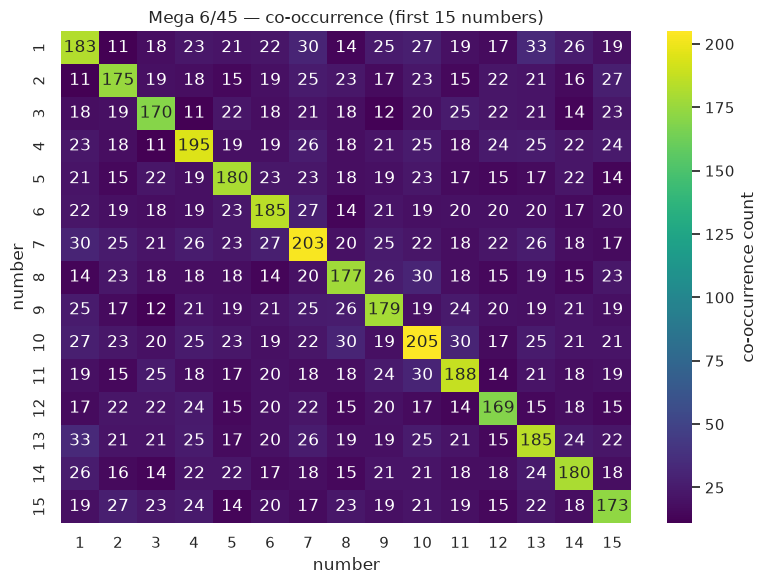

In [9]:
key = "mega645"
n_show = 15
co = cooccurrence(key)[:n_show, :n_show]
plt.figure(figsize=(8, 6))
sns.heatmap(
    co,
    annot=True,
    fmt="d",
    cmap="viridis",
    cbar_kws={"label": "co-occurrence count"},
    xticklabels=range(1, n_show + 1),
    yticklabels=range(1, n_show + 1),
)
plt.title(f"{LOTTERIES[key]['name']} — co-occurrence (first {n_show} numbers)")
plt.xlabel("number")
plt.ylabel("number")
plt.tight_layout()
plt.show()

## 7. Phân bố theo thời gian

Số kỳ theo năm và theo thứ trong tuần (mỗi sản phẩm có lịch quay cố định).

In [10]:
for k in LOTTERIES:
    draws = draws_by_lottery[k]
    dt = pd.to_datetime(pd.Series([d.date for d in draws], name="date"))
    print(f"### {LOTTERIES[k]['name']} — số kỳ theo năm")
    display(dt.dt.year.value_counts().sort_index().to_frame("n_draws").T)
    print("Theo thứ trong tuần")
    display(dt.dt.day_name().value_counts().to_frame("n_draws"))

### Mega 6/45 — số kỳ theo năm


date,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
n_draws,30,155,156,146,146,156,155,155,156,134


Theo thứ trong tuần


,n_draws
date,
Sunday,464
Wednesday,463
Friday,462


### Power 6/55 — số kỳ theo năm


date,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
n_draws,66,155,156,145,144,156,154,156,155,134


Theo thứ trong tuần


,n_draws
date,
Tuesday,474
Thursday,474
Saturday,473


## 8. Phân bố đặc trưng dùng cho mô hình

`make_tabular` tạo một mẫu cho mỗi cặp (kỳ, số) với 9 đặc trưng:
tần suất 5/10/20/50 kỳ, gap, số vừa về, tần suất toàn bộ, gap trung bình,
số lần xuất hiện.

In [11]:
print("Đặc trưng:", FEATURE_NAMES)

for k in LOTTERIES:
    tab = make_tabular(matrices[k])
    df = pd.DataFrame(tab.X, columns=tab.feature_names)
    print(
        f"### {LOTTERIES[k]['name']} — {len(df):,} mẫu (kỳ, số), "
        f"tỉ lệ nhãn dương = {tab.y.mean():.4f}"
    )
    display(df.describe().round(3))

Đặc trưng: ['freq_5', 'freq_10', 'freq_20', 'freq_50', 'gap', 'is_last', 'freq_all', 'avg_gap', 'n_appear']
### Mega 6/45 — 61,155 mẫu (kỳ, số), tỉ lệ nhãn dương = 0.1333


,freq_5,freq_10,freq_20,freq_50,gap,is_last,freq_all,avg_gap,n_appear
count,61155.000,61155.000,61155.000,61155.000,61155.000,61155.000,61155.000,61155.000,61155.000
mean,0.133,0.133,0.133,0.133,0.132,0.133,0.133,0.149,1.891
std,0.152,0.108,0.076,0.049,0.145,0.340,0.018,0.021,1.060
min,0.000,0.000,0.000,0.000,0.000,0.000,0.020,0.064,0.020
25%,0.000,0.100,0.100,0.100,0.040,0.000,0.124,0.138,0.980
50%,0.200,0.100,0.150,0.140,0.080,0.000,0.133,0.148,1.900
75%,0.200,0.200,0.200,0.160,0.180,0.000,0.143,0.159,2.800
max,1.000,0.700,0.500,0.360,1.400,1.000,0.288,0.490,4.100


### Power 6/55 — 76,505 mẫu (kỳ, số), tỉ lệ nhãn dương = 0.1091


,freq_5,freq_10,freq_20,freq_50,gap,is_last,freq_all,avg_gap,n_appear
count,76505.000,76505.000,76505.000,76505.000,76505.000,76505.000,76505.000,76505.000,76505.000
mean,0.109,0.109,0.109,0.109,0.162,0.109,0.109,0.182,1.582
std,0.139,0.098,0.069,0.043,0.169,0.312,0.015,0.027,0.890
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.067,0.000
25%,0.000,0.000,0.050,0.080,0.040,0.000,0.101,0.168,0.820
50%,0.000,0.100,0.100,0.100,0.100,0.000,0.109,0.180,1.580
75%,0.200,0.200,0.150,0.140,0.220,0.000,0.117,0.195,2.320
max,1.000,0.600,0.400,0.320,1.400,1.000,0.267,1.000,3.620


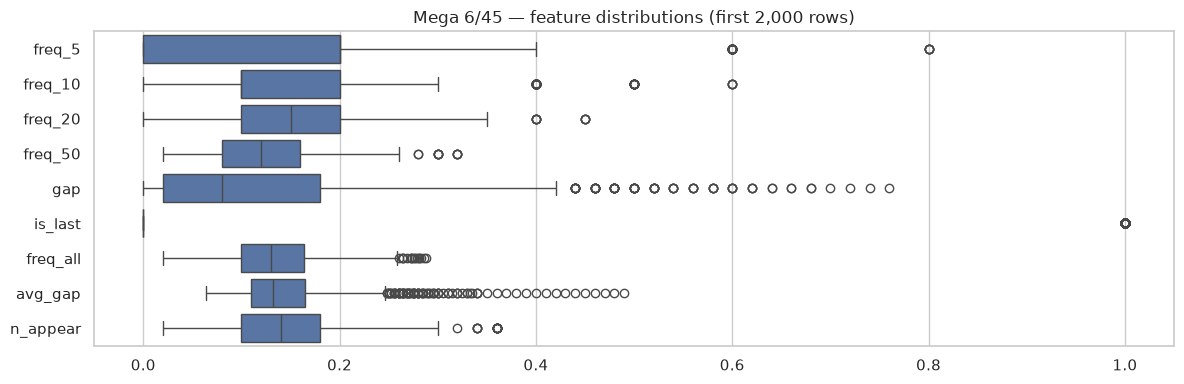

In [12]:
key = "mega645"
tab = make_tabular(matrices[key])
sample = pd.DataFrame(tab.X[:2000], columns=tab.feature_names)
plt.figure(figsize=(12, 4))
sns.boxplot(data=sample, orient="h", color="#4c72b0")
plt.title(f"{LOTTERIES[key]['name']} — feature distributions (first 2,000 rows)")
plt.tight_layout()
plt.show()

## 9. Nhận xét

- Tần suất từng số dao động quanh kỳ vọng ngẫu nhiên; không có số nào
  "chắc chắn" hơn số khác.
- Gap và tần suất gần đây chỉ là mô tả quá khứ, không mang thông tin dự báo.
- Đặc trưng dùng cho mô hình đều suy ra từ lịch sử, được xây dựng cẩn thận
  để **không rò rỉ tương lai** (chỉ dùng dữ liệu `0..t` để dự đoán `t+1`).

Chuyển sang `02_model_confusion_matrices.ipynb` để xem ma trận nhầm lẫn
của từng mô hình trên tập test.